# Function 8 — Week 9 full-cohort exploration

The 23 November snapshot contains 48 official observations and 26 published peer returns. 3 peer returns are new since 12 November.

[Model comparison](model_predictions.ipynb) · [Cohort review and next-query table](../../../../results/week-09-cohort-review.md)

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import sys

from IPython.display import display
import numpy as np
import pandas as pd

ANALYSIS_DIR = Path.cwd().resolve()
ROOT = next(path for path in ANALYSIS_DIR.parents if (path / "run-python.ps1").is_file())
EXPECTED_KERNEL = ROOT / ".venv" / ("Scripts/python.exe" if sys.platform == "win32" else "bin/python")
if Path(sys.executable).resolve() != EXPECTED_KERNEL.resolve():
    raise RuntimeError(f"Select the Capstone kernel: {EXPECTED_KERNEL}")
STAGE = ROOT / "stage-2-bbo"
SHARED = STAGE / "notebooks/Shared"
if str(SHARED) not in sys.path:
    sys.path.insert(0, str(SHARED))
from cohort_review_helpers import load_dated_cohort_review


In [2]:
FUNCTION_NUMBER = 8
INPUT_COLUMNS = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8']
EXPECTED_ROUND_COUNTS = {0: 40, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1}

In [3]:
OFFICIAL_DIR = ANALYSIS_DIR.parent / "official" if FUNCTION_NUMBER <= 4 else ANALYSIS_DIR.parent
OFFICIAL_CSV = OFFICIAL_DIR / "observations.csv"
SNAPSHOT = STAGE / "data/cohort/2026-11-23"
FIGURES = ANALYSIS_DIR / "figures"
FIGURES.mkdir(exist_ok=True)
review, intake = load_dated_cohort_review(SNAPSHOT, OFFICIAL_CSV, function=FUNCTION_NUMBER,
    input_columns=INPUT_COLUMNS, expected_round_counts=EXPECTED_ROUND_COUNTS)
official_data = review["own_data"]
peer_data = review["data"].loc[review["peer_mask"]]
display(pd.Series({"Official observations": len(official_data), "Published peer returns": len(peer_data),
    "New peer returns since 12 November": intake["new_peer"], "Total observations": len(review["data"])}))


Official observations                 48
Published peer returns                26
New peer returns since 12 November     3
Total observations                    74
dtype: int64

## Measured scores

The close-up shows the five highest scores. The latest marker follows the official record. Peer round labels are local to each reporting repository.

Round 8 return                      9.936773
Rank among official observations    1.000000
Rank in the full snapshot           5.000000
Best official score                 9.936773
Best published peer score           9.946588
dtype: float64

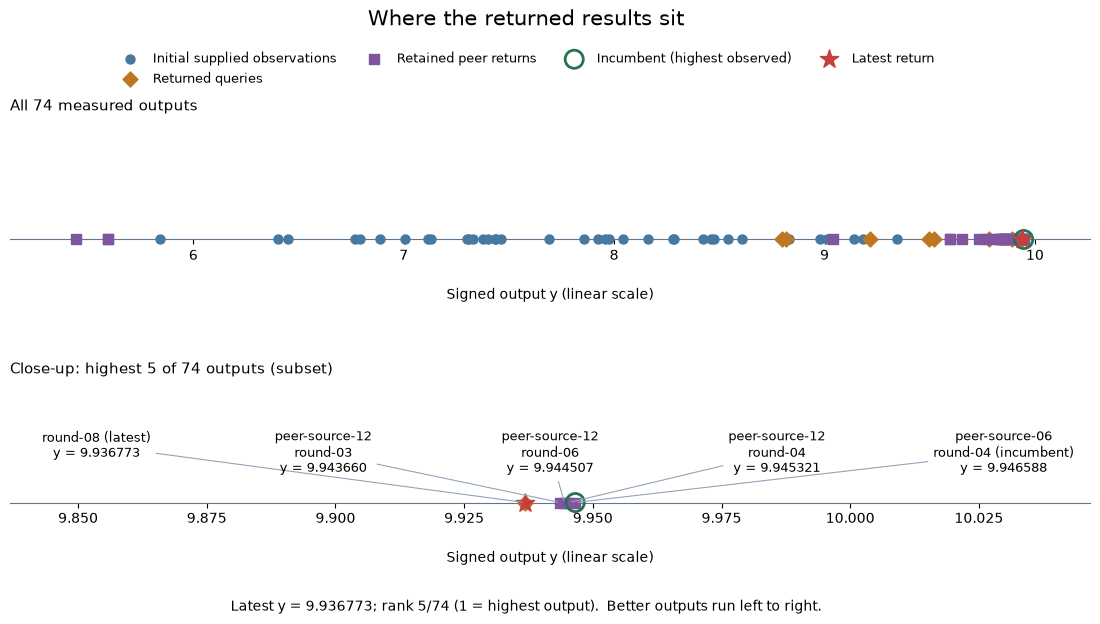

In [4]:
from observation_review_helpers import (
    prepare_weekly_observation_review, plot_output_review, plot_round_progress, plot_input_profiles,
)

prepared = prepare_weekly_observation_review(review, history=official_data)
latest = prepared["latest"]
latest_official_rank = int((official_data.y > latest.y).sum()) + 1
latest_cohort_rank = int((review["data"].y > latest.y).sum()) + 1
display(pd.Series({"Round 8 return": latest.y, "Rank among official observations": latest_official_rank,
    "Rank in the full snapshot": latest_cohort_rank, "Best official score": official_data.y.max(),
    "Best published peer score": peer_data.y.max()}))
display(plot_output_review(review, save_to=FIGURES / "observed-output-review.png"))


## Official progress

The running maximum follows the eight official returns.

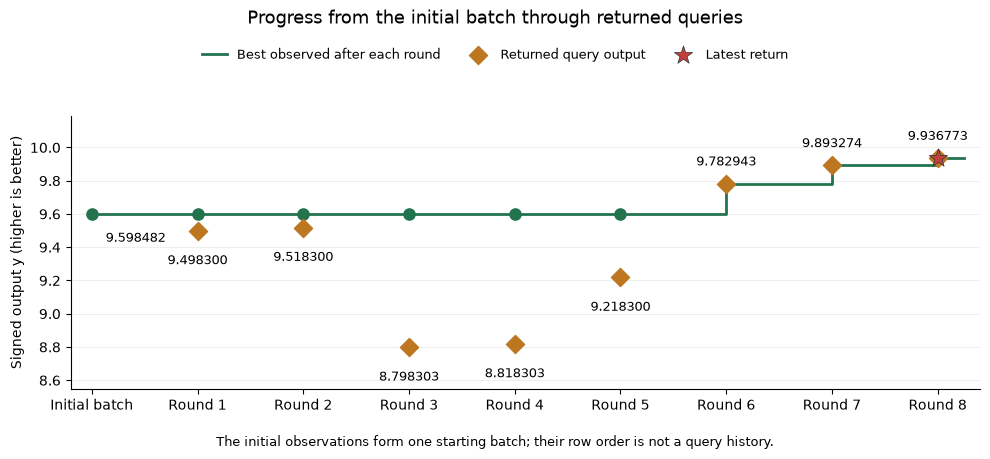

,returned_y,best_y,change_vs_prior_best
stage,,,
Initial batch,NaN,9.598482,NaN
Round 1,9.498300,9.598482,-0.100182
Round 2,9.518300,9.598482,-0.080182
Round 3,8.798303,9.598482,-0.800179
Round 4,8.818303,9.598482,-0.780179
Round 5,9.218300,9.598482,-0.380182
Round 6,9.782943,9.782943,0.184461
Round 7,9.893274,9.893274,0.110331
Round 8,9.936773,9.936773,0.043500


In [5]:
display(plot_round_progress(prepared["progress"], save_to=FIGURES / "official-progress.png"))
display(prepared["progress"].set_index("stage")[["returned_y", "best_y", "change_vs_prior_best"]])


## Strongest measured input profiles

Colour encodes input settings on a common 0–1 scale.

,rank,observation_id,x1,x2,x3,x4,x5,x6,x7,x8,y
62,1,peer-source-06-round-04,0.116000,0.065000,0.114000,0.022,0.912000,0.649000,0.201000,0.622000,9.946588
66,2,peer-source-12-round-04,0.126000,0.080000,0.166000,0.000,0.999999,0.503000,0.228000,0.532000,9.945321
73,3,peer-source-12-round-06,0.138700,0.056400,0.170700,0.000,0.968400,0.499500,0.223600,0.501300,9.944507
65,4,peer-source-12-round-03,0.125000,0.060000,0.160000,0.000,0.999999,0.490000,0.200000,0.470000,9.943660
47,5,round-08,0.042902,0.215002,0.170186,0.000,0.946758,0.586941,0.251883,0.480634,9.936773


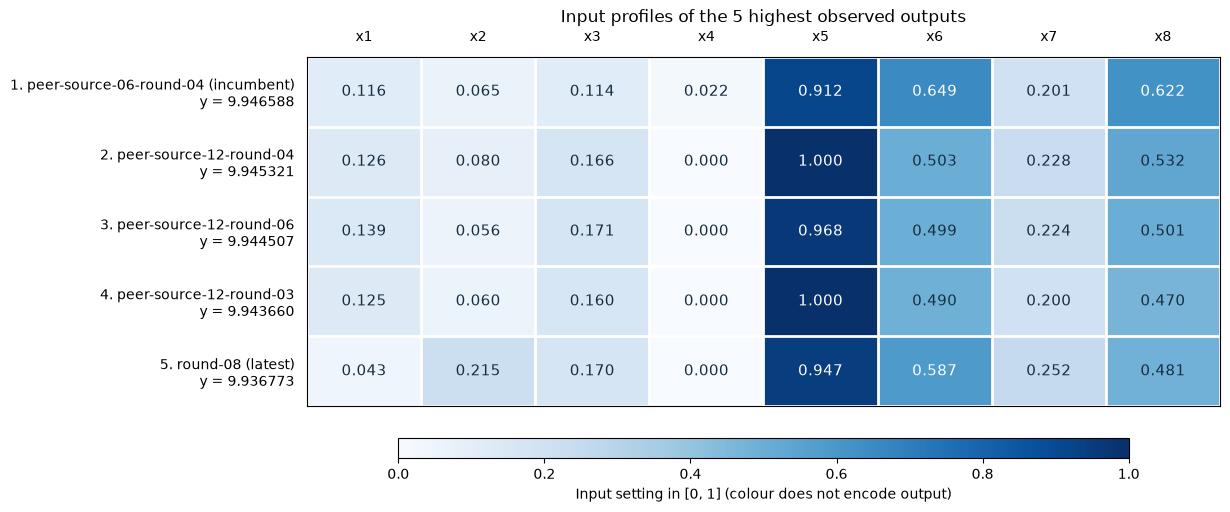

In [6]:
display(prepared["strongest"][["rank", "observation_id", *INPUT_COLUMNS, "y"]])
display(plot_input_profiles(prepared["strongest"], input_columns=INPUT_COLUMNS,
    latest_id=latest.observation_id, incumbent_id=prepared["incumbent"].observation_id,
    save_to=FIGURES / "strongest-input-profiles.png"))


In [7]:
summary = dict(function=FUNCTION_NUMBER, intake_date="2026-11-23",
    official_rows=intake["official"], peer_rows=intake["peer"], new_peer_rows=intake["new_peer"],
    latest_output=float(latest.y), latest_official_rank=latest_official_rank,
    latest_cohort_rank=latest_cohort_rank, official_best=float(official_data.y.max()),
    peer_best=float(peer_data.y.max()), best_peer_point=intake["peer_best_point"],
    official_snapshot_sha256=intake["official_sha256"], pooled_snapshot_sha256=intake["sha256"])
text = json.dumps(summary, indent=2, allow_nan=False)
(ANALYSIS_DIR / "observation-review.json").write_text(text + "\n", encoding="utf-8")
print(text)


{
  "function": 8,
  "intake_date": "2026-11-23",
  "official_rows": 48,
  "peer_rows": 26,
  "new_peer_rows": 3,
  "latest_output": 9.9367734246634,
  "latest_official_rank": 1,
  "latest_cohort_rank": 5,
  "official_best": 9.9367734246634,
  "peer_best": 9.9465876,
  "best_peer_point": [
    0.116,
    0.065,
    0.114,
    0.022,
    0.912,
    0.649,
    0.201,
    0.622
  ],
  "official_snapshot_sha256": "92f5e574057f3394df4069fc46aff1aab8452936a76aaff03a7d2e268b2c87d7",
  "pooled_snapshot_sha256": "052f8030fb79b7feb598483a2673217f3dfdce1b82c51ad659eb28198aed9a73"
}


## Preprocessing and validation diagnostics

Compare the middle half of each coordinate distribution and the empirical score distributions for official and published peer observations. Repeated groups use the rounded portal input across all coordinates. A peer at the same portal point as an official hold-out is withheld during validation. The model study tests median aggregation of training repeats and a higher assumed peer noise level. [Modelling experiments](model_predictions.ipynb#extended-cohort-surrogate-study)

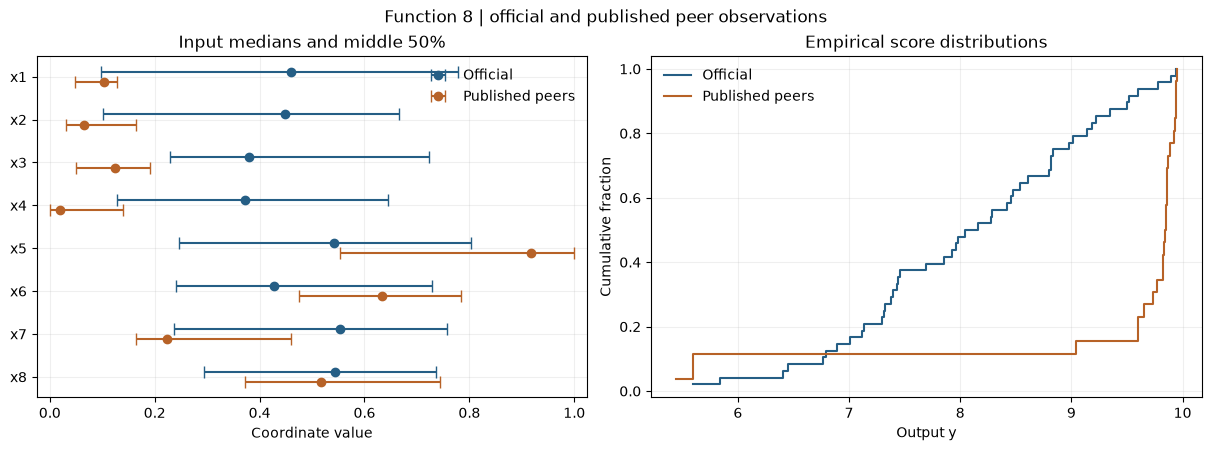

,scope,rows,rows_on_portal_boundary,score_median
0,Official,48,7,8.101098
1,Published peers,26,12,9.847013


portal_input_groups                 73.000000
repeated_input_groups                1.000000
peer_rows_matching_official          1.000000
median_peer_to_official_distance     0.289202
dtype: float64

In [8]:
from cohort_surrogate_plots import cohort_data_diagnostics

official_scores = official_data.y.to_numpy(dtype=float)
peer_scores = peer_data.y.to_numpy(dtype=float)
label = "Output y"
if FUNCTION_NUMBER == 1:
    function_helpers = STAGE / "notebooks/Function_1/FunctionSpecificShared"
    if str(function_helpers) not in sys.path:
        sys.path.insert(0, str(function_helpers))
    from function_1_model_helpers import signed_log
    official_scores = signed_log(official_scores, scale=1e-200)
    peer_scores = signed_log(peer_scores, scale=1e-200)
    label = "Signed-log height h"
diagnostics, distribution = cohort_data_diagnostics(review, official_scores, peer_scores,
    title=f"Function {FUNCTION_NUMBER} | official and published peer observations",
    target_label=label, save_to=FIGURES / "cohort-data-diagnostics.png")
display(distribution)
display(pd.DataFrame(diagnostics["by_scope"]))
display(pd.Series({key: value for key, value in diagnostics.items() if key != "by_scope"}))


### What the diagnostics show

Twelve of 26 peer rows touch a portal boundary, compared with seven of 48 official rows. The median nearest-official distance for a peer input is 0.289 in the eight-dimensional unit box. Observations on a boundary still leave many joint combinations unmeasured.
